# 70 — Imitation learning and covariate shift

Reinforcement learning discovers behavior from rewards. Imitation learning instead begins with examples from an expert. In this notebook we will train a small behavioral-cloning policy, observe why its own mistakes create unfamiliar states, and use a DAgger-style loop to collect corrective expert labels.

The grid world keeps the focus on the learning problem rather than robot-simulator details.

## Learning goals

- Distinguish imitation learning from reinforcement learning.
- Collect state–action demonstrations from an expert.
- Fit a tabular behavioral-cloning policy.
- Understand covariate shift and compounding errors.
- Evaluate policies in closed-loop rollouts rather than only on demonstration labels.
- Implement a small DAgger-style dataset aggregation loop.

In [2]:
from collections import deque
from dataclasses import dataclass

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import ListedColormap

from cs231n_practice.reinforcement_learning import (
    ACTION_DELTAS,
    ACTION_NAMES,
    GridWorld,
)

SEED = 42

## 1. Expert behavior

An expert provides a desired action for a state. Here the expert is not a neural network: it uses shortest-path distances computed backward from the goal. For each state, it selects an action leading to a neighboring state with a smaller distance.

In robotics, demonstrations might instead come from teleoperation, human motion, scripted controllers, or another trained policy.

In [3]:
def transition_from_state(environment, state, action):
    """Return the deterministic next state without mutating the environment."""
    candidate_array = np.asarray(state) + ACTION_DELTAS[action]
    candidate = (
        int(np.clip(candidate_array[0], 0, environment.height - 1)),
        int(np.clip(candidate_array[1], 0, environment.width - 1)),
    )
    return state if candidate in environment.obstacle_set else candidate


def shortest_path_distances(environment):
    """Calculate the number of steps from every reachable state to the goal."""
    distances = np.full((environment.height, environment.width), np.inf)
    distances[environment.goal] = 0.0
    queue = deque([environment.goal])

    while queue:
        state = queue.popleft()
        for action in range(len(ACTION_DELTAS)):
            neighbor = transition_from_state(environment, state, action)
            if neighbor != state and np.isinf(distances[neighbor]):
                distances[neighbor] = distances[state] + 1.0
                queue.append(neighbor)
    return distances


def make_expert_policy(environment):
    distances = shortest_path_distances(environment)

    def expert_policy(state, rng=None):
        del rng
        candidates = []
        for action in range(len(ACTION_DELTAS)):
            next_state = transition_from_state(environment, state, action)
            candidates.append(distances[next_state])
        return int(np.argmin(candidates))

    return expert_policy, distances


environment = GridWorld()
expert_policy, expert_distances = make_expert_policy(environment)
print("expert action at start:", ACTION_NAMES[expert_policy(environment.start)])

expert action at start: up


### Exercise 1 — Collect one expert demonstration

Record the state seen before every expert action, the selected action, and the complete trajectory. Stop at the goal or after `max_steps`.

In [4]:
def collect_demonstration(environment, policy, max_steps=100):
    state = environment.reset()
    states = []
    actions = []
    trajectory = [state]
    terminated = False

    for _ in range(max_steps):
        # query the policy, record the training pair, and step the environment.
        action = policy(state)
        next_state, _, terminated = environment.step(action)

        states.append(state)
        actions.append(action)
        trajectory.append(next_state)
        state = next_state
        if terminated:
            break

    return np.asarray(states), np.asarray(actions), trajectory, terminated


expert_states, expert_actions, expert_trajectory, expert_succeeded = (
    collect_demonstration(GridWorld(), expert_policy)
)
print("states:", expert_states)
print("actions:", [ACTION_NAMES[action] for action in expert_actions])
print("reached goal:", expert_succeeded)
assert expert_succeeded
assert len(expert_states) == 9

states: [[4 0]
 [3 0]
 [2 0]
 [1 0]
 [0 0]
 [0 1]
 [0 2]
 [0 3]
 [0 4]]
actions: ['up', 'up', 'up', 'up', 'right', 'right', 'right', 'right', 'right']
reached goal: True


## 2. Behavioral cloning

Behavioral cloning treats expert state–action pairs like a supervised dataset: the state is the input and the expert action is the label. Our tabular clone counts expert actions at each state and predicts the most frequent one.

This deliberately simple policy makes an important limitation visible: states absent from the demonstrations have no learned label. We use `right` as a fixed fallback for such states, but that fallback is not expert knowledge.

### Exercise 2 — Fit the tabular behavioral clone

In [5]:
@dataclass
class TabularClone:
    actions: np.ndarray
    known_states: np.ndarray
    fallback_action: int = 1

    def __call__(self, state, rng=None):
        del rng
        if self.known_states[state]:
            return int(self.actions[state])
        return self.fallback_action


def fit_tabular_clone(states, actions, height, width, fallback_action=1):
    action_counts = np.zeros((height, width, len(ACTION_DELTAS)), dtype=np.int64)
    # add one count for every demonstrated (state, action) pair.
    for state, action in zip(states, actions):
        row, column = state
        action_counts[row, column, action] += 1
    known_states = action_counts.sum(axis=2) > 0
    # choose the most frequent demonstrated action at every state.
    learned_actions = np.argmax(action_counts, axis=2)
    return TabularClone(learned_actions, known_states, fallback_action)


clone = fit_tabular_clone(
    expert_states,
    expert_actions,
    environment.height,
    environment.width,
)
training_predictions = np.array([clone(tuple(state)) for state in expert_states])
training_accuracy = np.mean(training_predictions == expert_actions)
print("demonstration action accuracy:", training_accuracy)
np.testing.assert_allclose(training_accuracy, 1.0, atol=1e-6)

demonstration action accuracy: 1.0


## 3. Covariate shift and compounding errors

Supervised training sees states generated by the **expert policy**. At deployment, however, states are generated by the **learned policy**. One imperfect or disturbed action can move the learner away from the expert trajectory into a state that was absent from its training data. A poor response there can cause another unfamiliar state, so errors may compound over time.

High action accuracy on the demonstration is therefore not enough. We must evaluate the policy in a closed loop, where its actions determine its future inputs. To expose recovery behavior, the rollout below occasionally replaces the requested action with a random disturbance.

### Exercise 3 — Implement disturbed closed-loop rollout

In [6]:
def rollout_with_disturbances(
    environment,
    policy,
    rng,
    disturbance_probability=0.1,
    max_steps=50,
):
    state = environment.reset()
    states = [state]
    requested_actions = []
    executed_actions = []
    terminated = False

    for _ in range(max_steps):
        requested_action = policy(state, rng)
        # replace the requested action randomly with the given probability.
        executed_action = requested_action
        if rng.random() < disturbance_probability:
            executed_action = rng.integers(0, len(ACTION_DELTAS))
        next_state, _, terminated = environment.step(executed_action)

        requested_actions.append(requested_action)
        executed_actions.append(executed_action)
        states.append(next_state)
        state = next_state
        if terminated:
            break

    return {
        "states": states,
        "requested_actions": requested_actions,
        "executed_actions": executed_actions,
        "terminated": terminated,
    }


def evaluate_policy(policy, number_episodes=200, disturbance_probability=0.1, max_steps=50, seed=SEED):
    rng = np.random.default_rng(seed)
    successes = []
    lengths = []
    for _ in range(number_episodes):
        rollout = rollout_with_disturbances(
            GridWorld(),
            policy,
            rng,
            disturbance_probability=disturbance_probability,
            max_steps=max_steps,
        )
        successes.append(rollout["terminated"])
        lengths.append(len(rollout["executed_actions"]))
    return np.mean(successes), np.mean(lengths)


for policy_name, policy in {"expert": expert_policy, "clone": clone}.items():
    clean_success, _ = evaluate_policy(policy, disturbance_probability=0.0)
    disturbed_success, disturbed_length = evaluate_policy(
        policy, disturbance_probability=0.2
    )
    print(
        f"{policy_name:6s}: clean={clean_success:.3f}, "
        f"disturbed={disturbed_success:.3f}, mean length={disturbed_length:.1f}"
    )

expert: clean=1.000, disturbed=1.000, mean length=11.2
clone : clean=1.000, disturbed=0.870, mean length=17.5


In [7]:
print("\nNow we will evaluate the policies with a shorter maximum rollout length of 15 steps.")
for policy_name, policy in {"expert": expert_policy, "clone": clone}.items():
    clean_success, _ = evaluate_policy(policy, disturbance_probability=0.0, max_steps=15)
    disturbed_success, disturbed_length = evaluate_policy(
        policy, disturbance_probability=0.2, max_steps=15
    )
    print(
        f"{policy_name:6s}: clean={clean_success:.3f}, "
        f"disturbed={disturbed_success:.3f}, mean length={disturbed_length:.1f}"
    )


Now we will evaluate the policies with a shorter maximum rollout length of 15 steps.
expert: clean=1.000, disturbed=0.965, mean length=11.1
clone : clean=1.000, disturbed=0.730, mean length=11.8


## 4. Visualize demonstration coverage

The visualization distinguishes states labeled by the expert demonstration from reachable states on which the clone only uses its fallback.

### Exercise 4 — Inspect the states covered by the demonstration

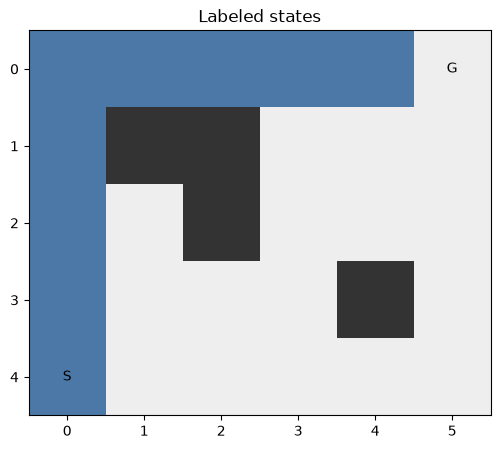

In [8]:
def plot_state_coverage(environment, known_states, axis=None, title="Labeled states"):
    if axis is None:
        _, axis = plt.subplots(figsize=(7, 5))
    display = known_states.astype(int)
    for obstacle in environment.obstacles:
        display[obstacle] = 2
    axis.imshow(display, cmap=ListedColormap(["#eeeeee", "#4c78a8", "#333333"]), vmin=0, vmax=2)
    axis.text(environment.start[1], environment.start[0], "S", ha="center", va="center")
    axis.text(environment.goal[1], environment.goal[0], "G", ha="center", va="center")
    axis.set_xticks(range(environment.width))
    axis.set_yticks(range(environment.height))
    axis.set_title(title)
    return axis


plot_state_coverage(GridWorld(), clone.known_states)
plt.show()

## 5. Dataset aggregation: DAgger intuition

DAgger addresses the expert/learner state-distribution mismatch iteratively:

1. train a policy on the current dataset;
2. run that policy so it visits states from its own distribution;
3. ask the expert which actions should be taken in those visited states;
4. add those corrected state–action pairs to the dataset and retrain.

The expert labels the learner's states; it does not need to have selected the actions that brought the learner there. Our small experiment keeps random disturbances during collection so the clone encounters recovery states.

### Exercise 5 — Aggregate corrective expert labels

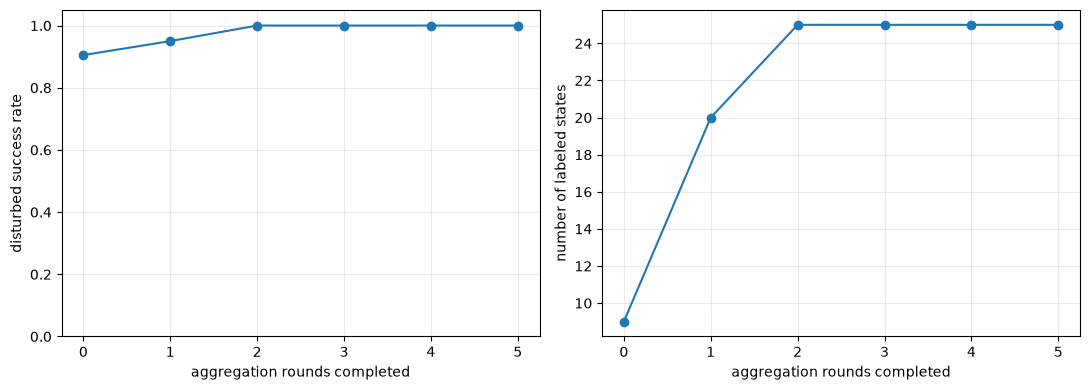

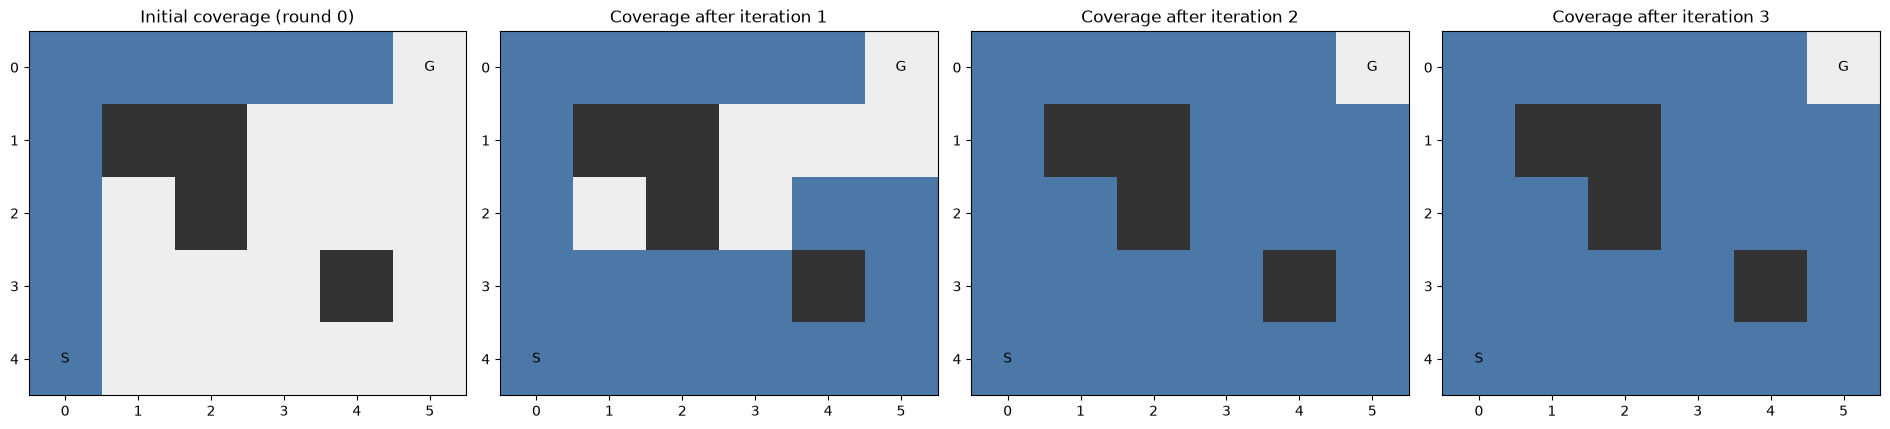

In [9]:
def train_with_dataset_aggregation(
    initial_states,
    initial_actions,
    expert_policy,
    number_iterations=5,
    rollouts_per_iteration=30,
    disturbance_probability=0.15,
    seed=SEED,
):
    rng = np.random.default_rng(seed)
    dataset_states = [tuple(state) for state in initial_states]
    dataset_actions = [int(action) for action in initial_actions]
    success_history = []
    coverage_history = []
    coverage_snapshots = []

    # Record the initial clone before any dataset aggregation (round 0).
    initial_clone = fit_tabular_clone(
        np.asarray(dataset_states),
        np.asarray(dataset_actions),
        GridWorld().height,
        GridWorld().width,
    )
    initial_success_rate, _ = evaluate_policy(
        initial_clone,
        disturbance_probability=disturbance_probability,
        seed=int(rng.integers(1_000_000)),
        max_steps=50,
    )
    success_history.append(initial_success_rate)
    coverage_history.append(initial_clone.known_states.sum())
    coverage_snapshots.append(initial_clone.known_states.copy())

    for _ in range(number_iterations):
        clone = fit_tabular_clone(
            np.asarray(dataset_states),
            np.asarray(dataset_actions),
            GridWorld().height,
            GridWorld().width,
        )
        for _ in range(rollouts_per_iteration):
            rollout = rollout_with_disturbances(
                GridWorld(),
                clone,
                rng,
                disturbance_probability=disturbance_probability,
                max_steps=15
            )
            # label every visited pre-action state with the expert.
            visited_states = [tuple(state) for state in rollout["states"][:-1]]
            # Ask the expert what should have been done in every learner-visited state.
            corrective_actions = [expert_policy(state) for state in visited_states]
            dataset_states.extend(visited_states)
            dataset_actions.extend(corrective_actions)

        # Refit and evaluate after this aggregation round.
        updated_clone = fit_tabular_clone(
            np.asarray(dataset_states),
            np.asarray(dataset_actions),
            GridWorld().height,
            GridWorld().width,
        )
        success_rate, _ = evaluate_policy(
            updated_clone,
            disturbance_probability=disturbance_probability,
            seed=int(rng.integers(1_000_000)),
            max_steps=50,
        )
        success_history.append(success_rate)
        coverage_history.append(updated_clone.known_states.sum())
        coverage_snapshots.append(updated_clone.known_states.copy())

    final_clone = fit_tabular_clone(
        np.asarray(dataset_states),
        np.asarray(dataset_actions),
        GridWorld().height,
        GridWorld().width,
    )
    return (
        final_clone,
        np.asarray(success_history),
        np.asarray(coverage_history),
        np.asarray(coverage_snapshots),
    )


(
    dagger_clone,
    dagger_success,
    dagger_coverage,
    dagger_coverage_snapshots,
) = train_with_dataset_aggregation(expert_states, expert_actions, expert_policy)

figure, axes = plt.subplots(1, 2, figsize=(11, 4))
aggregation_rounds = np.arange(len(dagger_success))
axes[0].plot(aggregation_rounds, dagger_success, "o-")
axes[0].set_xlabel("aggregation rounds completed")
axes[0].set_ylabel("disturbed success rate")
axes[0].set_ylim(0, 1.05)
axes[0].grid(alpha=0.25)
axes[1].plot(aggregation_rounds, dagger_coverage, "o-")
axes[1].set_xlabel("aggregation rounds completed")
axes[1].set_ylabel("number of labeled states")
axes[1].grid(alpha=0.25)
plt.tight_layout()
plt.show()

figure, axes = plt.subplots(1, 4, figsize=(19, 4))
coverage_titles = [
    "Initial coverage (round 0)",
    "Coverage after iteration 1",
    "Coverage after iteration 2",
    "Coverage after iteration 3",
]
for snapshot_index, (axis, title) in enumerate(zip(axes, coverage_titles)):
    plot_state_coverage(
        GridWorld(),
        dagger_coverage_snapshots[snapshot_index],
        axis=axis,
        title=title,
    )
plt.tight_layout()
plt.show()

## 6. Compare robustness across disturbance levels

Evaluation at several disturbance probabilities separates clean imitation from recovery. The expert is an upper reference for this environment, not a claim that real human demonstrations are perfect.

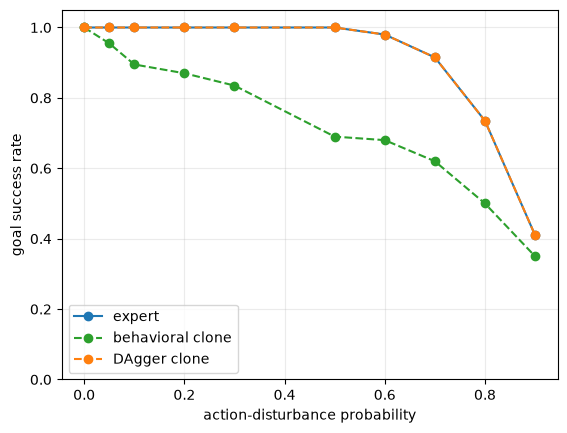

In [31]:
disturbance_levels = np.array([0.0, 0.05, 0.10, 0.20, 0.30, 0.50, 0.60, 0.70, 0.80, 0.90])
policies = {"expert": expert_policy, "behavioral clone": clone, "DAgger clone": dagger_clone}
success_by_policy = {}

for policy_name, policy in policies.items():
    success_by_policy[policy_name] = np.array([
        evaluate_policy(
            policy, disturbance_probability=probability, seed=SEED
        )[0]
        for probability in disturbance_levels
    ])

for policy_name, success_rates in success_by_policy.items():
    style = "o-" if policy_name == "expert" else "o--"
    color = "C0" if policy_name == "expert" else "C2" if policy_name == "behavioral clone" else "C1"
    plt.plot(disturbance_levels, success_rates, style, label=policy_name, color=color)
plt.xlabel("action-disturbance probability")
plt.ylabel("goal success rate")
plt.ylim(0, 1.05)
plt.grid(alpha=0.25)
plt.legend()
plt.show()

## 7. What this toy experiment leaves out

A real imitation-learning system may use images, language, proprioception, and continuous robot actions rather than a tiny state table. Expert queries can also be costly, and executing an imperfect learner to collect DAgger data may be unsafe. The core distinction nevertheless remains: ordinary behavioral cloning trains on expert-visited inputs, while interactive data aggregation deliberately obtains labels for states induced by the learner.

See [Imitation learning, behavioral cloning, and DAgger](../notes/17-robot-learning/imitation-learning-behavioral-cloning-and-dagger.md) for a concise conceptual summary.

## Reflection

1. How does behavioral cloning turn policy learning into supervised learning?

   _Your answer:_

2. Why can perfect action accuracy on an expert demonstration still produce a weak closed-loop policy?

   _Your answer:_

3. What is covariate shift in this imitation-learning experiment?

   _Your answer:_

4. Why can one prediction mistake lead to several later mistakes?

   _Your answer:_

5. What new information does DAgger add to the training dataset?

   _Your answer:_

6. Why might applying DAgger directly on a physical robot be risky or expensive?

   _Your answer:_